# Trabalho Prático TP1: Análise Exploratória de Duas Bases Reais

* **Disciplina:** Ciência de Dados 1
* **Professor:** Márcio Palheta Piedade, D.Sc.
* **Curso:** Sistemas de Informação (EST/UEA)
* **Período:** 2026/02
* **Aluno:** Henrique da Silva Furtado

**Bases analisadas**

* **Base 1: Netflix Movies and TV Shows** ([Kaggle: shivamb/netflix-shows](https://www.kaggle.com/datasets/shivamb/netflix-shows)),
  arquivo **`netflix_titles.csv`**: catálogo da Netflix com 8.807 filmes e séries (dados até set/2021).
* **Base 2: Students Performance in Exams** ([Kaggle: spscientist/students-performance-in-exams](https://www.kaggle.com/spscientist/students-performance-in-exams)),
  arquivo **`StudentsPerformance.csv`**: notas de Matemática, Leitura e Escrita de 1.000 estudantes.

Os dois CSVs estão na raiz do repositório, ao lado deste notebook (podem ser baixados de novo com
`python scripts/baixar_bases.py`).

**Regras seguidas neste notebook**

* Toda a manipulação é feita com **Pandas** (DataFrames, leitura de arquivos, seleção, filtros,
  indexação, agrupamentos e estatísticas) e todos os gráficos com **Matplotlib**.
* Todo gráfico tem título, rótulos dos eixos e legenda quando há mais de uma série; cada entidade
  (Movie/TV Show, gênero, curso preparatório) mantém sempre a mesma cor ao longo do notebook.
* As conclusões são **descritivas** (sem testes de hipótese, conforme o enunciado).
* O notebook é executável do início ao fim (Kernel → Restart & Run All).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.precision", 2)

plt.rcParams["figure.figsize"] = (10, 4.8)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["figure.max_open_warning"] = 0

# Paleta categórica em ordem fixa: cada entidade mantém a mesma cor em todos os gráficos.
AZUL, LARANJA, VERDE_AGUA, AMARELO, VIOLETA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7"
CINZA = "#898781"
COR_TIPO = {"Movie": AZUL, "TV Show": LARANJA}
COR_GENERO = {"female": AZUL, "male": LARANJA}
COR_CURSO = {"completed": VERDE_AGUA, "none": CINZA}


def explodir(df, coluna, nome):
    """Uma linha por valor de uma coluna multivalorada separada por vírgula (ex.: country, director)."""
    out = df.assign(**{nome: df[coluna].str.split(",")}).explode(nome, ignore_index=True)
    out[nome] = out[nome].str.strip()
    return out[out[nome].notna() & (out[nome] != "")]


def rotular_barras(ax, barras, fmt="{:,.0f}"):
    """Escreve o valor na ponta de cada barra."""
    ax.bar_label(barras, labels=[fmt.format(v) for v in barras.datavalues], padding=3, fontsize=9)

# BASE 1: NETFLIX MOVIES AND TV SHOWS

## 1. Conhecendo e preparando os dados

### 1.1 Carga do arquivo CSV

In [2]:
netflix = pd.read_csv("netflix_titles.csv")
print("Arquivo carregado:", type(netflix))

Arquivo carregado: <class 'pandas.DataFrame'>


### 1.2 Quantidade de linhas e colunas

In [3]:
linhas, colunas = netflix.shape
print(f"Linhas  : {linhas:,}")
print(f"Colunas : {colunas}")

Linhas  : 8,807
Colunas : 12


### 1.3 Cinco primeiras e cinco últimas linhas

In [4]:
display(netflix.head())
display(netflix.tail())

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


### 1.4 Colunas existentes

In [5]:
for i, c in enumerate(netflix.columns, start=1):
    print(f"{i:>2}. {c}")

 1. show_id
 2. type
 3. title
 4. director
 5. cast
 6. country
 7. date_added
 8. release_year
 9. rating
10. duration
11. listed_in
12. description


### 1.5 Tipos de dados

In [6]:
print(netflix.dtypes)
print("\nResumo:", netflix.dtypes.value_counts().to_dict())

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

Resumo: {<StringDtype(storage='python', na_value=nan)>: 11, dtype('int64'): 1}


Apenas `release_year` é numérica (`int64`); todas as demais, inclusive `date_added` (data) e
`duration` (número + unidade), foram lidas como texto e precisam de conversão para serem
analisadas numericamente.

### 1.6 Valores ausentes por coluna

In [7]:
ausentes = pd.DataFrame({
    "ausentes": netflix.isna().sum(),
    "percentual (%)": netflix.isna().mean() * 100,
}).sort_values("ausentes", ascending=False)
display(ausentes)

,ausentes,percentual (%)
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


### 1.7 Registros duplicados

In [8]:
print("Linhas totalmente duplicadas         :", netflix.duplicated().sum())
print("show_id repetidos                    :", netflix["show_id"].duplicated().sum())
print("Mesmo título, tipo e ano repetidos   :", netflix.duplicated(subset=["title", "type", "release_year"]).sum())
print("Títulos repetidos (somente o título) :", netflix["title"].duplicated().sum())

Linhas totalmente duplicadas         : 0
show_id repetidos                    : 0
Mesmo título, tipo e ano repetidos   : 0
Títulos repetidos (somente o título) : 0


Não há duplicatas: nem linhas idênticas, nem identificadores (`show_id`) repetidos, nem o mesmo
título cadastrado duas vezes. Cada linha corresponde a uma produção distinta.

### 1.8 Descrição inicial da base

In [9]:
display(netflix.describe())                       # única coluna numérica: release_year
display(netflix.describe(exclude="number").T)     # colunas de texto: contagem, únicos, mais frequente

,release_year
count,8807.00
mean,2014.18
std,8.82
min,1925.00
25%,2013.00
50%,2017.00
75%,2019.00
max,2021.00


,count,unique,top,freq
show_id,8807,8807,s1,1
type,8807,2,Movie,6131
title,8807,8807,Dick Johnson Is Dead,1
director,6173,4528,Rajiv Chilaka,19
cast,7982,7692,David Attenborough,19
country,7976,748,United States,2818
date_added,8797,1767,"January 1, 2020",109
rating,8803,17,TV-MA,3207
duration,8804,220,1 Season,1793
listed_in,8807,514,"Dramas, International Movies",362


In [10]:
print("Valores distintos por coluna:")
print(netflix.nunique().sort_values())

Valores distintos por coluna:
type               2
rating            17
release_year      74
duration         220
listed_in        514
country          748
date_added      1767
director        4528
cast            7692
description     8775
show_id         8807
title           8807
dtype: int64


### 1.9 Características e problemas encontrados nos dados

1. **Muitos valores ausentes em `director` (29,9 %), `country` (9,4 %) e `cast` (9,4 %).**
   Qualquer ranking de diretores ou países é feito sobre um subconjunto da base; quase um terço
   das produções não tem diretor informado (a ausência é muito maior em séries, que costumam
   ter vários diretores por temporada).
2. **Colunas multivaloradas.** `country`, `director`, `cast` e `listed_in` guardam listas
   separadas por vírgula ("United States, India"). Contar valores diretamente trata
   "United States" e "United States, India" como países diferentes; é preciso "explodir" a
   lista em uma linha por valor.
3. **Três registros com colunas deslocadas.** Em três especiais de Louis C.K. a duração
   ("74 min") foi gravada em `rating` e `duration` ficou vazia; por isso `rating` tem 17
   valores distintos, três deles que não são classificações.
4. **`duration` mistura unidades e tipos**: minutos para filmes ("90 min") e temporadas
   para séries ("2 Seasons"), sempre como texto. Não dá para calcular estatísticas sem separar
   número e unidade e sem tratar filmes e séries separadamente.
5. **`date_added` é texto em inglês** ("September 25, 2021"), com 88 registros iniciados por um
   espaço extra e 10 ausentes; é preciso limpar e converter para `datetime`.
6. **`release_year` concentrada em anos recentes** (mediana 2017, mínimo 1925): é uma base de
   catálogo, não de produção mundial, e os dados terminam em setembro de 2021 (ano incompleto).

A célula abaixo aplica os tratamentos (2) a (5), gerando `netflix_tratado`, usado no restante da
análise. O DataFrame original é preservado.

In [11]:
netflix_tratado = netflix.copy()

# (3) duração gravada na coluna rating: devolve para duration e anula rating
deslocado = netflix_tratado["rating"].str.contains("min", na=False)
print("Registros com rating deslocado:")
display(netflix_tratado.loc[deslocado, ["title", "rating", "duration"]])
netflix_tratado.loc[deslocado, "duration"] = netflix_tratado.loc[deslocado, "rating"]
netflix_tratado.loc[deslocado, "rating"] = np.nan

# (5) date_added: remove espaços e converte para data
print("date_added iniciados por espaço:", netflix_tratado["date_added"].str.startswith(" ").sum())
netflix_tratado["data_adicao"] = pd.to_datetime(netflix_tratado["date_added"].str.strip(), format="%B %d, %Y")
netflix_tratado["ano_adicao"] = netflix_tratado["data_adicao"].dt.year.astype("Int64")

# (4) duration: separa o número e cria uma coluna para cada tipo
unidade = netflix_tratado["duration"].str.split().str[1]
print("\nUnidades de duration por tipo:")
print(pd.crosstab(netflix_tratado["type"], unidade))
numero = netflix_tratado["duration"].str.extract(r"(\d+)")[0].astype("Int64")
netflix_tratado["duracao_min"] = numero.where(netflix_tratado["type"] == "Movie")
netflix_tratado["temporadas"] = numero.where(netflix_tratado["type"] == "TV Show")

# (2) colunas multivaloradas: quantos registros têm mais de um valor
print()
for col in ["country", "director", "cast", "listed_in"]:
    pct = netflix_tratado[col].str.contains(",", na=False).mean() * 100
    print(f"{col:<10}: {pct:5.1f} % dos registros têm mais de um valor")

print("\nApós o tratamento:")
print("  rating distintos   :", netflix_tratado["rating"].nunique())
print("  duration ausentes  :", netflix_tratado["duration"].isna().sum())
print("  data_adicao        :", netflix_tratado["data_adicao"].min().date(), "a", netflix_tratado["data_adicao"].max().date())

Registros com rating deslocado:


,title,rating,duration
5541,Louis C.K. 2017,74 min,NaN
5794,Louis C.K.: Hilarious,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,66 min,NaN


date_added iniciados por espaço: 88

Unidades de duration por tipo:
duration  Season  Seasons   min
type                           
Movie          0        0  6131
TV Show     1793      883     0

country   :  15.0 % dos registros têm mais de um valor
director  :   7.0 % dos registros têm mais de um valor
cast      :  80.6 % dos registros têm mais de um valor
listed_in :  77.1 % dos registros têm mais de um valor

Após o tratamento:
  rating distintos   : 14
  duration ausentes  : 0
  data_adicao        : 2008-01-01 a 2021-09-25


## 2. Investigação dos dados

### 2.1 Quantos registros correspondem a Movies e quantos a TV Shows?

In [12]:
contagem_tipo = netflix_tratado["type"].value_counts()
percentual_tipo = netflix_tratado["type"].value_counts(normalize=True) * 100
display(pd.DataFrame({"títulos": contagem_tipo, "percentual (%)": percentual_tipo}))
print(f"Há {contagem_tipo['Movie'] / contagem_tipo['TV Show']:.2f} filmes para cada série.")

,títulos,percentual (%)
type,,
Movie,6131,69.62
TV Show,2676,30.38


Há 2.29 filmes para cada série.


**Interpretação.** O catálogo é dominado por filmes: 6.131 (69,6 %) contra 2.676 séries
(30,4 %), cerca de 2,3 filmes para cada série. Essa proporção conta *títulos*, não horas de
conteúdo: uma série com várias temporadas ocupa muito mais tempo de tela do que um filme.

### 2.2 Quais são os 10 países com maior quantidade de produções?

Como `country` é multivalorada, a contagem é feita após explodir a lista: uma coprodução
"United States, India" conta uma vez para cada país. Registros sem país (831) ficam de fora.

In [13]:
paises = explodir(netflix_tratado, "country", "pais")
top10_paises = paises["pais"].value_counts().head(10)

comparacao = pd.DataFrame({
    "com coproduções": top10_paises,
    "só o texto original": netflix_tratado["country"].value_counts(),
}).loc[top10_paises.index].astype("Int64")
display(comparacao)
print(f"Países distintos após explodir: {paises['pais'].nunique()} "
      f"(contra {netflix_tratado['country'].nunique()} combinações de texto na coluna original)")

,com coproduções,só o texto original
pais,,
United States,3690,2818
India,1046,972
United Kingdom,806,419
Canada,445,181
France,393,124
Japan,318,245
Spain,232,145
South Korea,231,199
Germany,226,67


Países distintos após explodir: 122 (contra 748 combinações de texto na coluna original)


**Interpretação.** Os Estados Unidos aparecem em 3.690 produções, mais que o triplo da Índia
(1.046), segunda colocada; Reino Unido (806), Canadá (445) e França (393) completam o top 5.
A comparação com a contagem "ingênua" mostra por que explodir importa: Reino Unido, Canadá,
França e Alemanha participam muito de coproduções, e a contagem pelo texto original os
subestima pela metade ou mais (Reino Unido cai de 806 para 419; França de 393 para 124;
Alemanha de 226 para 67). Já a Índia quase não coproduz (1.046 × 972). Os 748 textos distintos
da coluna original correspondem, na verdade, a 122 países.

### 2.3 Quais são os 10 diretores com maior quantidade de produções?

In [14]:
diretores = explodir(netflix_tratado, "director", "diretor")
top10_diretores = diretores["diretor"].value_counts().head(10)
display(top10_diretores.to_frame("produções"))

# Que tipo de produção cada um dirige?
display(pd.crosstab(diretores["diretor"], diretores["type"]).loc[top10_diretores.index])

,produções
diretor,
Rajiv Chilaka,22
Jan Suter,21
Raúl Campos,19
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,15
Cathy Garcia-Molina,13
Youssef Chahine,12
Martin Scorsese,12


type,Movie,TV Show
diretor,,
Rajiv Chilaka,22,0
Jan Suter,21,0
Raúl Campos,19,0
Suhas Kadav,16,0
Marcus Raboy,15,1
Jay Karas,15,0
Cathy Garcia-Molina,13,0
Youssef Chahine,12,0
Martin Scorsese,12,0


**Interpretação.** O topo é formado por diretores de nicho, não por nomes de Hollywood:
Rajiv Chilaka (22, animações infantis indianas como *Chhota Bheem*), Jan Suter (21) e
Raúl Campos (19), dupla responsável por dezenas de especiais de *stand-up* latino-americanos,
e Suhas Kadav (16, também animação indiana). Martin Scorsese e Steven Spielberg aparecem com
12 e 11 títulos. Como 30 % das produções não têm diretor informado (quase todas as séries),
esse ranking descreve sobretudo os **filmes**.

### 2.4 Quais são as 5 classificações (rating) mais frequentes?

In [15]:
top5_rating = netflix_tratado["rating"].value_counts().head(5)
display(pd.DataFrame({
    "títulos": top5_rating,
    "percentual (%)": top5_rating / netflix_tratado["rating"].notna().sum() * 100,
}))
print(f"As 5 classificações somam {top5_rating.sum() / netflix_tratado['rating'].notna().sum() * 100:.1f} % dos títulos classificados.")

,títulos,percentual (%)
rating,,
TV-MA,3207,36.44
TV-14,2160,24.55
TV-PG,863,9.81
R,799,9.08
PG-13,490,5.57


As 5 classificações somam 85.4 % dos títulos classificados.


**Interpretação.** TV-MA (conteúdo adulto, 36,4 %) e TV-14 (24,6 %) somam mais de 60 % do
catálogo; seguem TV-PG, R e PG-13. As 5 classificações reúnem 85,4 % dos títulos.
O catálogo é, portanto, voltado principalmente a adultos e adolescentes, e classificações
de TV (TV-*) predominam até entre filmes, porque o sistema de TV dos EUA é usado para
produções lançadas direto em *streaming*.

### 2.5 Quantas produções foram lançadas em cada ano?

In [16]:
por_ano = netflix_tratado["release_year"].value_counts().sort_index()
print(f"Anos distintos: {por_ano.size} ({por_ano.index.min()} a {por_ano.index.max()})")
print(f"Ano com mais lançamentos: {por_ano.idxmax()} ({por_ano.max():,} títulos)\n")

# tabela completa: uma coluna por ano
display(por_ano.to_frame("títulos").T)

Anos distintos: 74 (1925 a 2021)
Ano com mais lançamentos: 2018 (1,147 títulos)



release_year,1925,1942,1943,1944,1945,1946,1947,1954,1955,1956,1958,1959,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
títulos,1,2,3,3,4,2,1,2,3,2,3,1,4,1,3,2,2,2,1,5,3,2,2,5,5,10,7,7,9,7,7,11,11,13,17,11,12,10,13,8,18,16,22,17,23,28,22,25,24,38,36,39,37,45,51,61,64,80,96,88,136,152,194,185,237,288,352,560,902,1032,1147,1030,953,592


**Interpretação.** Há títulos de 74 anos distintos, de 1925 a 2021, mas a distribuição é muito
desigual: até 1990 quase todos os anos têm menos de 30 títulos, e o volume cresce rapidamente a
partir de 2014, com pico em **2018 (1.147 títulos)**. A queda em 2019-2021 não significa menos
produção: 2021 está incompleto (dados até setembro) e títulos recentes ainda não tinham sido
licenciados quando a base foi coletada. A distribuição reflete a estratégia de catálogo da
Netflix, concentrada em conteúdo recente.

### 2.6 Qual década apresenta a maior quantidade de títulos?

In [17]:
netflix_tratado["decada"] = netflix_tratado["release_year"] // 10 * 10
por_decada = netflix_tratado["decada"].value_counts().sort_index()
display(pd.DataFrame({"títulos": por_decada, "percentual (%)": por_decada / por_decada.sum() * 100}))
print(f"Década com mais títulos: {por_decada.idxmax()}s ({por_decada.max():,} títulos)")

,títulos,percentual (%)
decada,,
1920,1,0.01
1940,15,0.17
1950,11,0.12
1960,25,0.28
1970,70,0.79
1980,129,1.46
1990,274,3.11
2000,810,9.20
2010,5927,67.30


Década com mais títulos: 2010s (5,927 títulos)


**Interpretação.** A década de **2010** concentra 5.927 títulos, 67,3 % de toda a base; somada
aos dois anos de 2020-2021 (1.545), chega a 85 %. Todas as décadas anteriores a 2000 juntas
somam menos de 6 %. O catálogo é essencialmente contemporâneo.

### 2.7 Considerando somente filmes, quais são as 10 durações mais frequentes?

In [18]:
filmes = netflix_tratado[netflix_tratado["type"] == "Movie"]
top10_duracoes = filmes["duracao_min"].value_counts().head(10)
display(top10_duracoes.rename_axis("duração (min)").to_frame("filmes"))
print(filmes["duracao_min"].describe().round(1))

,filmes
duração (min),
90,152
94,146
97,146
93,146
91,144
95,137
96,130
92,129
102,122


count    6131.0
mean       99.6
std        28.3
min         3.0
25%        87.0
50%        98.0
75%       114.0
max       312.0
Name: duracao_min, dtype: Float64


**Interpretação.** As durações mais frequentes estão todas entre 90 e 102 minutos: 90 min
(152 filmes) lidera, seguido de 93, 94 e 97 min (146 cada). A diferença entre as dez primeiras
é pequena, ou seja, não há uma duração "padrão", mas uma faixa típica de cerca de 1h30 a
1h45. Isso é coerente com a mediana de 98 min; o desvio de ~28 min e o mínimo de 3 min / máximo
de 312 min mostram que também há curtas e filmes muito longos na base.

### 2.8 Qual é o filme mais antigo da base? E o mais recente?

In [19]:
colunas_ver = ["title", "director", "country", "release_year", "date_added"]

ano_mais_antigo = filmes["release_year"].min()
print(f"Filme(s) mais antigo(s): lançado(s) em {ano_mais_antigo}")
display(filmes.loc[filmes["release_year"] == ano_mais_antigo, colunas_ver])

ano_mais_recente = filmes["release_year"].max()
recentes = filmes[filmes["release_year"] == ano_mais_recente]
print(f"Ano mais recente: {ano_mais_recente}, com {len(recentes)} filmes empatados.")
print("Desempate pela data de adição ao catálogo (o(s) último(s) adicionado(s)):")
display(recentes.loc[recentes["data_adicao"] == recentes["data_adicao"].max(), colunas_ver])

print("Observação: o título mais antigo de toda a base é uma série:")
display(netflix_tratado.nsmallest(1, "release_year")[["type"] + colunas_ver])

Filme(s) mais antigo(s): lançado(s) em 1942


,title,director,country,release_year,date_added
7790,Prelude to War,Frank Capra,United States,1942,"March 31, 2017"
8205,The Battle of Midway,John Ford,United States,1942,"March 31, 2017"


Ano mais recente: 2021, com 277 filmes empatados.
Desempate pela data de adição ao catálogo (o(s) último(s) adicionado(s)):


,title,director,country,release_year,date_added
6,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha",NaN,2021,"September 24, 2021"
9,The Starling,Theodore Melfi,United States,2021,"September 24, 2021"


Observação: o título mais antigo de toda a base é uma série:


,type,title,director,country,release_year,date_added
4250,TV Show,Pioneers: First Women Filmmakers*,NaN,NaN,1925,"December 30, 2018"


**Interpretação.** Os filmes mais antigos são de **1942**, dois documentários da Segunda Guerra:
*Prelude to War* (Frank Capra) e *The Battle of Midway* (John Ford), ambos adicionados em
31/03/2017 junto com uma coleção de documentários de guerra. No outro extremo, **277 filmes**
foram lançados em 2021, o ano mais recente, então "o mais recente" não é único pelo ano; usando a
data de adição como desempate, os últimos a entrar no catálogo foram
***My Little Pony: A New Generation*** e ***The Starling***, ambos em 24/09/2021 (a data mais
recente de filmes na base). Vale notar que o título mais antigo da base inteira
não é um filme, e sim a série documental *Pioneers: First Women Filmmakers* (1925), por isso
a pergunta exige filtrar por `type == "Movie"` antes.

## 3. Visualização dos dados

### Gráfico 1: Quantidade de Movies × TV Shows

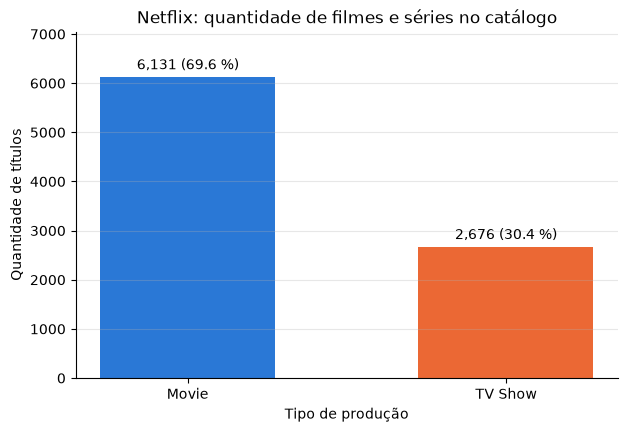

In [20]:
fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(contagem_tipo.index, contagem_tipo.values,
                color=[COR_TIPO[t] for t in contagem_tipo.index], width=0.55)
ax.bar_label(barras, labels=[f"{v:,} ({p:.1f} %)" for v, p in zip(contagem_tipo, percentual_tipo)], padding=3)
ax.set_title("Netflix: quantidade de filmes e séries no catálogo")
ax.set_xlabel("Tipo de produção")
ax.set_ylabel("Quantidade de títulos")
ax.set_ylim(0, contagem_tipo.max() * 1.15)
ax.grid(axis="x", visible=False)
plt.show()

Os filmes são mais que o dobro das séries (69,6 % × 30,4 %). Como as duas categorias estão
identificadas no eixo X, a legenda é dispensável.

### Gráfico 2: Top 10 países com mais produções

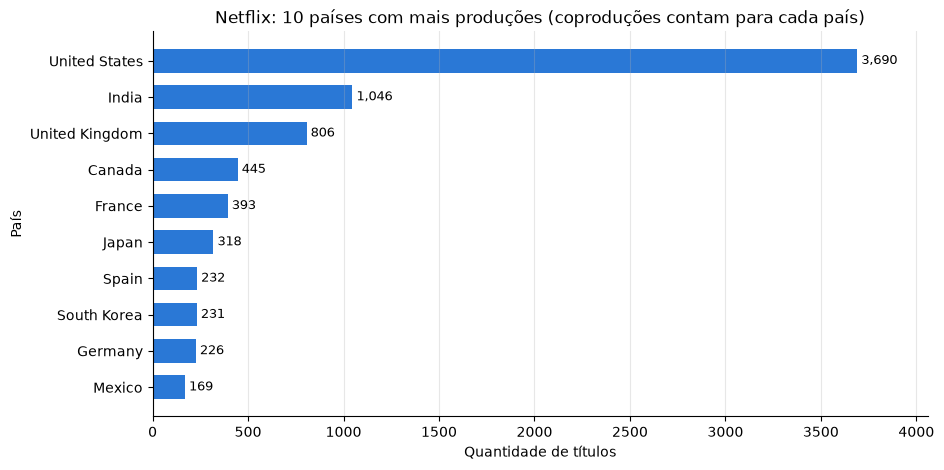

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
dados = top10_paises.sort_values()                       # barra maior no topo
barras = ax.barh(dados.index, dados.values, color=AZUL, height=0.65)
rotular_barras(ax, barras)
ax.set_title("Netflix: 10 países com mais produções (coproduções contam para cada país)")
ax.set_xlabel("Quantidade de títulos")
ax.set_ylabel("País")
ax.set_xlim(0, dados.max() * 1.1)
ax.grid(axis="y", visible=False)
plt.show()

Barras horizontais deixam os nomes dos países legíveis. A distância entre os EUA e o restante é
o destaque: a Índia, segunda colocada, tem menos de um terço das produções norte-americanas.

### Gráfico 3: Quantidade de títulos por ano

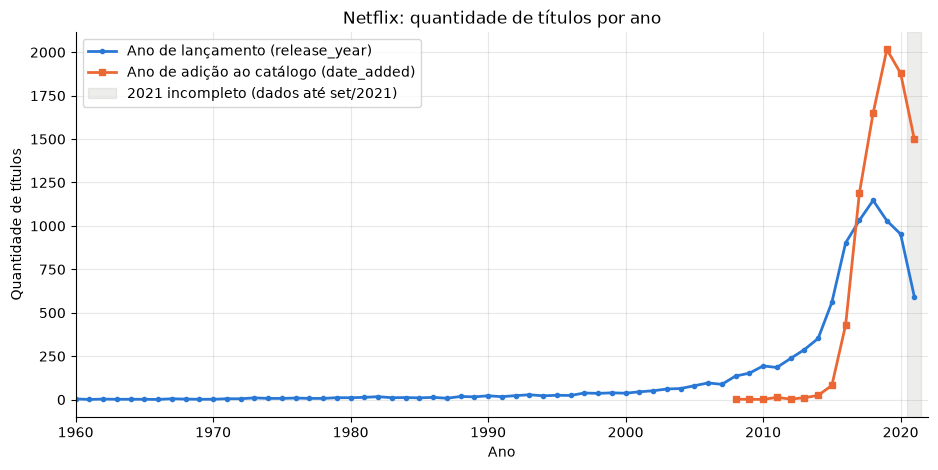

In [22]:
por_ano_adicao = netflix_tratado["ano_adicao"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(por_ano.index, por_ano.values, color=AZUL, linewidth=2, marker="o", markersize=3,
        label="Ano de lançamento (release_year)")
ax.plot(por_ano_adicao.index, por_ano_adicao.values, color=LARANJA, linewidth=2, marker="s", markersize=4,
        label="Ano de adição ao catálogo (date_added)")
ax.axvspan(2020.5, 2021.5, color=CINZA, alpha=0.15, label="2021 incompleto (dados até set/2021)")
ax.set_title("Netflix: quantidade de títulos por ano")
ax.set_xlabel("Ano")
ax.set_ylabel("Quantidade de títulos")
ax.set_xlim(1960, 2022)
ax.legend(loc="upper left")
plt.show()

O recorte começa em 1960 porque antes disso há no máximo 5 títulos por ano. Comparar as duas
séries mostra como o catálogo foi montado: o número de títulos **lançados** por ano cresce a
partir de 2014 e atinge o pico em 2018, enquanto o número de títulos **adicionados** só decola
em 2016 e chega ao máximo em 2019 (2.016). Antes de 2016 quase nada foi adicionado, embora
existam milhares de títulos lançados antes disso: os filmes antigos entraram no catálogo
tardiamente, por licenciamento (ver Investigação livre, pergunta 2).

### Gráfico 4 (livre escolha): Gêneros mais frequentes no catálogo

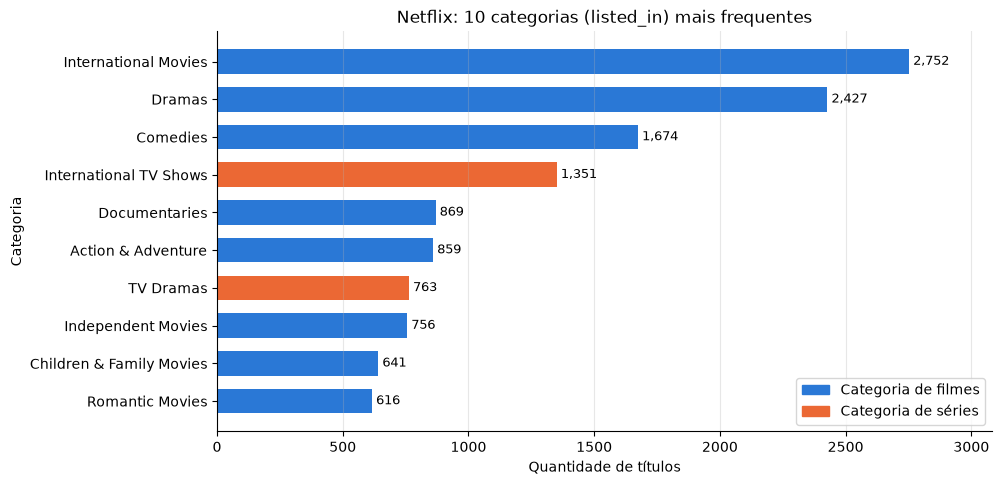

Títulos em alguma categoria 'International': 46.6 %


In [23]:
generos = explodir(netflix_tratado, "listed_in", "genero")
top10_generos = generos["genero"].value_counts().head(10)
# cada categoria do catálogo pertence a filmes ou a séries ("TV Dramas", "Dramas"...)
tipo_genero = generos.groupby("genero")["type"].agg(lambda s: s.mode()[0])

dados = top10_generos.sort_values()
fig, ax = plt.subplots(figsize=(10, 5.2))
barras = ax.barh(dados.index, dados.values, color=[COR_TIPO[tipo_genero[g]] for g in dados.index], height=0.65)
rotular_barras(ax, barras)
ax.set_title("Netflix: 10 categorias (listed_in) mais frequentes")
ax.set_xlabel("Quantidade de títulos")
ax.set_ylabel("Categoria")
ax.set_xlim(0, dados.max() * 1.12)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=AZUL, label="Categoria de filmes"),
                   Patch(color=LARANJA, label="Categoria de séries")], loc="lower right")
plt.show()
print(f"Títulos em alguma categoria 'International': "
      f"{netflix_tratado['listed_in'].str.contains('International').mean() * 100:.1f} %")

As categorias de `listed_in` são específicas de cada tipo ("Dramas" para filmes,
"TV Dramas" para séries), por isso as barras são coloridas pelo tipo. **International Movies**
lidera (2.752 títulos) e International TV Shows é a 4ª (1.351): 46,6 % do catálogo está em
alguma categoria "International", o que mostra o peso das produções de fora dos EUA, apesar da
liderança americana no Gráfico 2. Entre os gêneros propriamente ditos, drama e comédia dominam,
seguidos de documentários e ação/aventura. Só 2 das 10 categorias são de séries, coerente com
a proporção de 70/30 entre filmes e séries.

# BASE 2: STUDENTS PERFORMANCE IN EXAMS

## 4. Conhecendo e preparando os dados

### 4.1 Carga do CSV

In [24]:
alunos = pd.read_csv("StudentsPerformance.csv")

NOTAS = ["math score", "reading score", "writing score"]
NOME_NOTA = {"math score": "Matemática", "reading score": "Leitura", "writing score": "Escrita",
             "media_geral": "Média geral"}
print("Arquivo carregado:", type(alunos))

Arquivo carregado: <class 'pandas.DataFrame'>


### 4.2 head() e tail()

In [25]:
display(alunos.head())
display(alunos.tail())

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


### 4.3 Quantidade de linhas e colunas

In [26]:
print(f"Linhas  : {alunos.shape[0]:,}")
print(f"Colunas : {alunos.shape[1]}")

Linhas  : 1,000
Colunas : 8


### 4.4 Tipos das colunas

In [27]:
print(alunos.dtypes)
print("\nCategorias de cada coluna de texto:")
for col in alunos.select_dtypes(exclude="number").columns:
    print(f"  {col:<28}: {sorted(alunos[col].unique())}")

gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

Categorias de cada coluna de texto:
  gender                      : ['female', 'male']
  race/ethnicity              : ['group A', 'group B', 'group C', 'group D', 'group E']
  parental level of education : ["associate's degree", "bachelor's degree", 'high school', "master's degree", 'some college', 'some high school']
  lunch                       : ['free/reduced', 'standard']
  test preparation course     : ['completed', 'none']


As três notas são inteiras (`int64`, escala 0 a 100); as cinco colunas restantes são categóricas
(texto), com 2 a 6 categorias cada.

### 4.5 Valores ausentes

In [28]:
print(alunos.isna().sum())
print("\nTotal de valores ausentes:", alunos.isna().sum().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Total de valores ausentes: 0


### 4.6 Registros duplicados

In [29]:
print("Linhas duplicadas:", alunos.duplicated().sum())

Linhas duplicadas: 0


A base está completa (nenhum valor ausente) e sem linhas duplicadas, portanto nenhuma limpeza é
necessária. (Ela é uma base sintética amplamente usada para ensino, o que explica estar "limpa".)

### 4.7 describe()

In [30]:
display(alunos.describe())
display(alunos.describe(exclude="number"))

,math score,reading score,writing score
count,1000.00,1000.00,1000.00
mean,66.09,69.17,68.05
std,15.16,14.60,15.20
min,0.00,17.00,10.00
25%,57.00,59.00,57.75
50%,66.00,70.00,69.00
75%,77.00,79.00,79.00
max,100.00,100.00,100.00


,gender,race/ethnicity,parental level of education,lunch,test preparation course
count,1000,1000,1000,1000,1000
unique,2,5,6,2,2
top,female,group C,some college,standard,none
freq,518,319,226,645,642


### 4.8 Média e mediana das três notas

In [31]:
resumo_notas = alunos[NOTAS].agg(["mean", "median"]).T.rename(index=NOME_NOTA, columns={"mean": "média", "median": "mediana"})
resumo_notas["média − mediana"] = resumo_notas["média"] - resumo_notas["mediana"]
display(resumo_notas)

,média,mediana,média − mediana
Matemática,66.09,66.0,0.09
Leitura,69.17,70.0,-0.83
Escrita,68.05,69.0,-0.95


**Informações relevantes obtidas com o `describe()`**

1. **As médias ficam entre 66 e 69 pontos e são muito próximas das medianas** (Matemática 66,1
   × 66; Leitura 69,2 × 70; Escrita 68,1 × 69). Em Leitura e Escrita a média é ligeiramente menor
   que a mediana, sinal de uma leve assimetria à esquerda: há alguns alunos com notas bem baixas
   puxando a média para baixo.
2. **Matemática é a disciplina de pior desempenho em todos os quartis**: média e mediana mais
   baixas, Q1 = 57 e o único **zero** da base (mínimo 0, contra 17 em Leitura e 10 em Escrita).
   Esse zero é um valor atípico que merece atenção.
3. **A dispersão é parecida nas três disciplinas** (desvio padrão de 14,6 a 15,2 pontos); metade
   dos alunos fica numa faixa de ~20 pontos (de Q1 ≈ 57-59 a Q3 ≈ 77-79), e todas as disciplinas
   têm pelo menos um aluno com nota máxima (100).
4. Entre as categóricas, os valores mais frequentes são: sexo feminino (518), grupo C (319), pais
   com *some college* (226), almoço padrão (645) e **não ter feito o curso preparatório (642)**.

## 5. Análise do desempenho dos estudantes

### 5.1 Média das notas de Matemática, Leitura e Escrita

In [32]:
medias = alunos[NOTAS].mean().rename(NOME_NOTA)
print(medias.round(2))

Matemática    66.09
Leitura       69.17
Escrita       68.05
dtype: float64


### 5.2 Mediana de cada disciplina

In [33]:
medianas = alunos[NOTAS].median().rename(NOME_NOTA)
print(medianas)

Matemática    66.0
Leitura       70.0
Escrita       69.0
dtype: float64


### 5.3 Disciplina com a maior média

In [34]:
print(f"Maior média: {medias.idxmax()} ({medias.max():.2f})")
print(f"Menor média: {medias.idxmin()} ({medias.min():.2f})")

Maior média: Leitura (69.17)
Menor média: Matemática (66.09)


**Interpretação (5.1 a 5.3).** Leitura tem a maior média (69,17) e a maior mediana (70),
seguida de Escrita (68,05 / 69) e Matemática (66,09 / 66). A diferença entre a melhor e a pior
disciplina é de cerca de 3 pontos, pequena frente ao desvio padrão de ~15 pontos: as
disciplinas têm níveis parecidos, com Matemática um pouco abaixo.

### 5.4 Nova coluna `media_geral`

In [35]:
alunos["media_geral"] = alunos[NOTAS].mean(axis=1)
display(alunos[NOTAS + ["media_geral"]].head())
print(alunos["media_geral"].describe().round(2))
print(f"\nCorrelação entre as notas:")
print(alunos[NOTAS].corr().rename(index=NOME_NOTA, columns=NOME_NOTA).round(2))

,math score,reading score,writing score,media_geral
0,72,72,74,72.67
1,69,90,88,82.33
2,90,95,93,92.67
3,47,57,44,49.33
4,76,78,75,76.33


count    1000.00
mean       67.77
std        14.26
min         9.00
25%        58.33
50%        68.33
75%        77.67
max       100.00
Name: media_geral, dtype: float64

Correlação entre as notas:
            Matemática  Leitura  Escrita
Matemática        1.00     0.82     0.80
Leitura           0.82     1.00     0.95
Escrita           0.80     0.95     1.00


**Interpretação.** A `media_geral` é a média simples das três notas de cada aluno (peso igual).
Sua média (67,77) é a média das três disciplinas e sua dispersão (desvio de 14,3) é só um pouco
menor que a de cada prova, porque as notas são fortemente correlacionadas (0,80 a 0,95, com
Leitura e Escrita quase idênticas): quem vai bem em uma prova costuma ir bem nas outras, então
a média geral resume bem o desempenho do aluno.

### 5.5 Os 10 estudantes com maior média geral

In [36]:
top10_alunos = alunos.nlargest(10, "media_geral")
display(top10_alunos)
empatados = alunos.nlargest(10, "media_geral", keep="all")
print(f"Atenção: {len(empatados)} alunos têm média >= {top10_alunos['media_geral'].min():.2f} "
      f"(empate na 10ª posição); nlargest mantém os 10 primeiros pela ordem do arquivo.\n")
print("Perfil do top 10:")
for col in ["gender", "race/ethnicity", "lunch", "test preparation course"]:
    print(f"  {col:<24}: {top10_alunos[col].value_counts().to_dict()}")

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,media_geral
458,female,group E,bachelor's degree,standard,none,100,100,100,100.00
916,male,group E,bachelor's degree,standard,completed,100,100,100,100.00
962,female,group E,associate's degree,standard,none,100,100,100,100.00
114,female,group E,bachelor's degree,standard,completed,99,100,100,99.67
179,female,group D,some high school,standard,completed,97,100,100,99.00
712,female,group D,some college,standard,none,98,100,99,99.00
165,female,group C,bachelor's degree,standard,completed,96,100,100,98.67
625,male,group D,some college,standard,completed,100,97,99,98.67
149,male,group E,associate's degree,free/reduced,completed,100,100,93,97.67
685,female,group E,master's degree,standard,completed,94,99,100,97.67


Atenção: 11 alunos têm média >= 97.67 (empate na 10ª posição); nlargest mantém os 10 primeiros pela ordem do arquivo.

Perfil do top 10:
  gender                  : {'female': 7, 'male': 3}
  race/ethnicity          : {'group E': 6, 'group D': 3, 'group C': 1}
  lunch                   : {'standard': 9, 'free/reduced': 1}
  test preparation course : {'completed': 7, 'none': 3}


**Interpretação.** Três estudantes tiraram 100 nas três provas. Há empate na 10ª posição
(três alunos com 97,67), então o "top 10" exato inclui um critério de desempate (ordem do arquivo). O top 10 é formado
majoritariamente por meninas (7 de 10) e por alunos dos grupos D e E (9 de 10), e quase todos têm
almoço padrão (*standard*, 9 de 10). Sete dos dez completaram o curso preparatório, mas ele não
é condição para chegar ao topo: duas das três alunas com nota 100 em tudo não o fizeram.

### 5.6 Percentual de aprovados (média geral ≥ 70)

In [37]:
alunos["aprovado"] = alunos["media_geral"] >= 70
n_aprovados = alunos["aprovado"].sum()
print(f"Aprovados  : {n_aprovados} de {len(alunos)} ({alunos['aprovado'].mean() * 100:.1f} %)")
print(f"Reprovados : {len(alunos) - n_aprovados} ({(1 - alunos['aprovado'].mean()) * 100:.1f} %)")

Aprovados  : 459 de 1000 (45.9 %)
Reprovados : 541 (54.1 %)


**Interpretação.** Apenas **45,9 %** dos estudantes atingem média 70. Como a média geral da turma
(67,8) fica abaixo da linha de corte, a maioria (54,1 %) seria reprovada por esse critério.

### 5.7 Média geral por gênero

In [38]:
por_genero = alunos.groupby("gender")[NOTAS + ["media_geral"]].mean().rename(columns=NOME_NOTA)
por_genero["aprovação (%)"] = alunos.groupby("gender")["aprovado"].mean() * 100
display(por_genero)

,Matemática,Leitura,Escrita,Média geral,aprovação (%)
gender,,,,,
female,63.63,72.61,72.47,69.57,51.74
male,68.73,65.47,63.31,65.84,39.63


**Interpretação.** As meninas têm média geral maior (69,57 × 65,84) e maior taxa de aprovação.
Mas a vantagem **não vale para todas as disciplinas**: os meninos vão melhor em Matemática
(68,73 × 63,63, +5,1), enquanto as meninas vão melhor em Leitura (+7,1) e Escrita (+9,2). Como
duas das três provas favorecem as meninas, a média geral também as favorece.

### 5.8 Curso preparatório: completaram × não completaram

In [39]:
por_curso = alunos.groupby("test preparation course")[NOTAS + ["media_geral"]].mean().rename(columns=NOME_NOTA)
por_curso.loc["diferença"] = por_curso.loc["completed"] - por_curso.loc["none"]
por_curso["aprovação (%)"] = alunos.groupby("test preparation course")["aprovado"].mean() * 100
display(por_curso)

,Matemática,Leitura,Escrita,Média geral,aprovação (%)
test preparation course,,,,,
completed,69.70,73.89,74.42,72.67,60.89
none,64.08,66.53,64.50,65.04,37.54
diferença,5.62,7.36,9.91,7.63,NaN


**Interpretação.** Quem completou o curso preparatório tem média geral 7,6 pontos maior
(72,67 × 65,04) e é aprovado com muito mais frequência. A diferença aparece nas três provas, mas
é maior em Escrita (+9,9) e menor em Matemática (+5,6). Por ser uma análise descritiva, não dá
para afirmar que o curso *causa* a melhora: quem faz o curso pode diferir em outros aspectos.

### 5.9 Média geral por nível de escolaridade dos pais

In [40]:
ORDEM_ESCOLARIDADE = ["some high school", "high school", "some college",
                      "associate's degree", "bachelor's degree", "master's degree"]
por_escolaridade = (alunos.groupby("parental level of education")
                    .agg(alunos=("media_geral", "size"), media_geral=("media_geral", "mean"),
                         aprovacao=("aprovado", "mean"))
                    .reindex(ORDEM_ESCOLARIDADE))
por_escolaridade["aprovacao"] *= 100
display(por_escolaridade)

,alunos,media_geral,aprovacao
parental level of education,,,
some high school,179,65.11,41.34
high school,196,63.10,33.16
some college,226,68.48,47.79
associate's degree,222,69.57,49.55
bachelor's degree,118,71.92,55.93
master's degree,59,73.60,61.02


**Interpretação.** Ordenando do menor para o maior nível de escolaridade dos pais, a média
geral sobe quase continuamente: de ~63-65 (ensino médio incompleto/completo) para 71,9
(*bachelor's*) e 73,6 (*master's*), uma diferença de 10,5 pontos entre o pior e o melhor nível.
Curiosamente, *high school* (63,10) fica abaixo de *some high school* (65,11). Os grupos têm
tamanhos bem diferentes: *master's degree* tem só 59 alunos, então sua média é menos estável.

### 5.10 Grupo (race/ethnicity) com maior média geral

In [41]:
por_grupo = alunos.groupby("race/ethnicity").agg(alunos=("media_geral", "size"),
                                                 media_geral=("media_geral", "mean"))
display(por_grupo.sort_values("media_geral", ascending=False))
print(f"Grupo com maior média geral: {por_grupo['media_geral'].idxmax()} ({por_grupo['media_geral'].max():.2f})")

,alunos,media_geral
race/ethnicity,,
group E,140,72.75
group D,262,69.18
group C,319,67.13
group B,190,65.47
group A,89,62.99


Grupo com maior média geral: group E (72.75)


**Interpretação.** O **grupo E** tem a maior média geral (72,75), e a média cresce em ordem
alfabética de A (62,99) a E. A base não informa o que cada grupo representa (os rótulos são
anônimos), então essa diferença só pode ser descrita, não explicada.

## 6. Visualização dos dados

### Gráfico 1: Distribuição das notas de Matemática

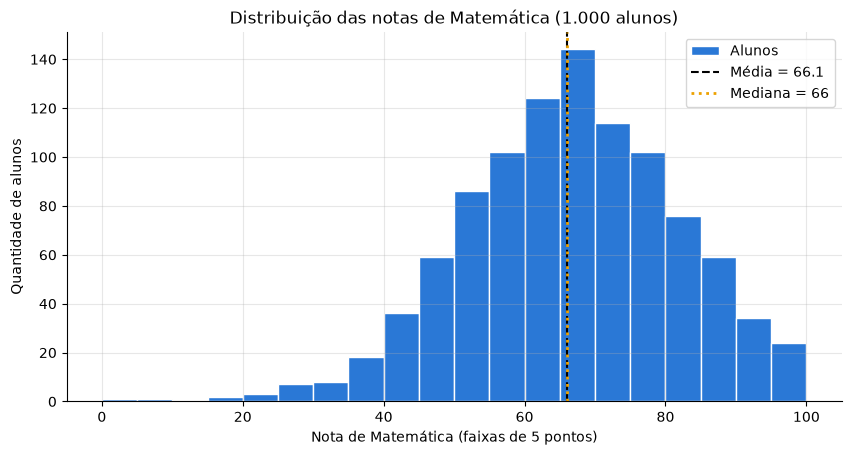

Alunos com nota < 40: 40 | nota >= 90: 58


In [42]:
mat = alunos["math score"]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(mat, bins=range(0, 105, 5), color=AZUL, edgecolor="white", label="Alunos")
ax.axvline(mat.mean(), color="black", linestyle="--", linewidth=1.5, label=f"Média = {mat.mean():.1f}")
ax.axvline(mat.median(), color=AMARELO, linestyle=":", linewidth=2, label=f"Mediana = {mat.median():.0f}")
ax.set_title("Distribuição das notas de Matemática (1.000 alunos)")
ax.set_xlabel("Nota de Matemática (faixas de 5 pontos)")
ax.set_ylabel("Quantidade de alunos")
ax.legend()
plt.show()
print(f"Alunos com nota < 40: {(mat < 40).sum()} | nota >= 90: {(mat >= 90).sum()}")

A distribuição tem forma de sino, centrada entre 60 e 75 pontos, com média (66,1) e mediana (66)
praticamente iguais, o que indica uma distribuição aproximadamente simétrica. A cauda esquerda é
mais longa que a direita: algumas dezenas de alunos ficam abaixo de 40 e há um caso isolado de
nota 0, enquanto a direita termina em 100.

### Gráfico 2: Comparação das médias de Matemática, Leitura e Escrita

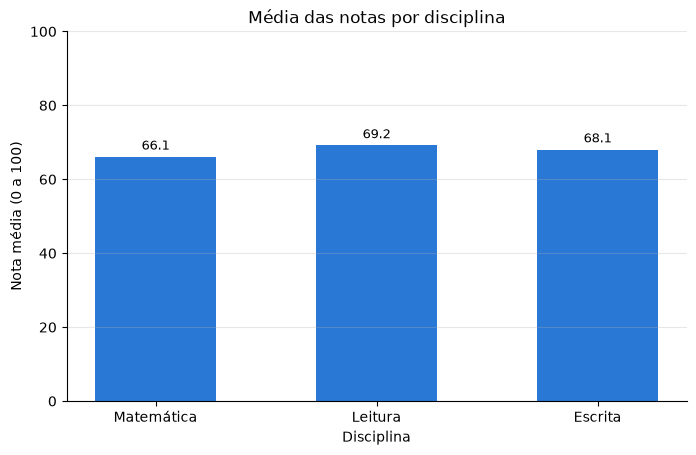

In [43]:
fig, ax = plt.subplots(figsize=(8, 4.8))
barras = ax.bar(medias.index, medias.values, color=AZUL, width=0.55)
rotular_barras(ax, barras, "{:.1f}")
ax.set_title("Média das notas por disciplina")
ax.set_xlabel("Disciplina")
ax.set_ylabel("Nota média (0 a 100)")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
plt.show()

Com o eixo Y completo (0 a 100), as três médias aparecem muito próximas: Leitura (69,2) e
Escrita (68,1) praticamente empatam e Matemática (66,1) fica cerca de 3 pontos abaixo. O eixo
começa em zero de propósito: truncá-lo exageraria uma diferença que é pequena.

### Gráfico 3: Média geral por gênero

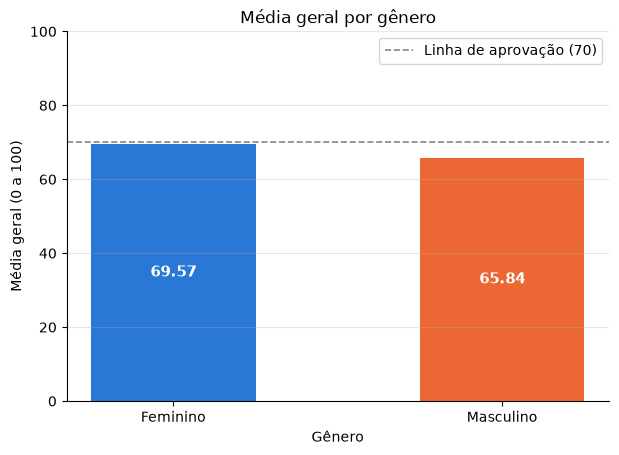

In [44]:
media_genero = alunos.groupby("gender")["media_geral"].mean()
rotulo_genero = {"female": "Feminino", "male": "Masculino"}

fig, ax = plt.subplots(figsize=(7, 4.8))
barras = ax.bar([rotulo_genero[g] for g in media_genero.index], media_genero.values,
                color=[COR_GENERO[g] for g in media_genero.index], width=0.5)
ax.bar_label(barras, fmt="%.2f", label_type="center", color="white", fontsize=11, fontweight="bold")
ax.axhline(70, color=CINZA, linestyle="--", linewidth=1.2, label="Linha de aprovação (70)")
ax.set_title("Média geral por gênero")
ax.set_xlabel("Gênero")
ax.set_ylabel("Média geral (0 a 100)")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
plt.show()

As meninas têm média geral 3,7 pontos maior (69,57 × 65,84), mas **nenhum dos dois grupos
alcança, em média, a linha de aprovação**, ainda que o feminino fique muito perto dela. Esse
gráfico de médias esconde a inversão por disciplina vista em 5.7, explorada no Gráfico 5.

### Gráfico 4: Média dos estudantes com e sem curso preparatório

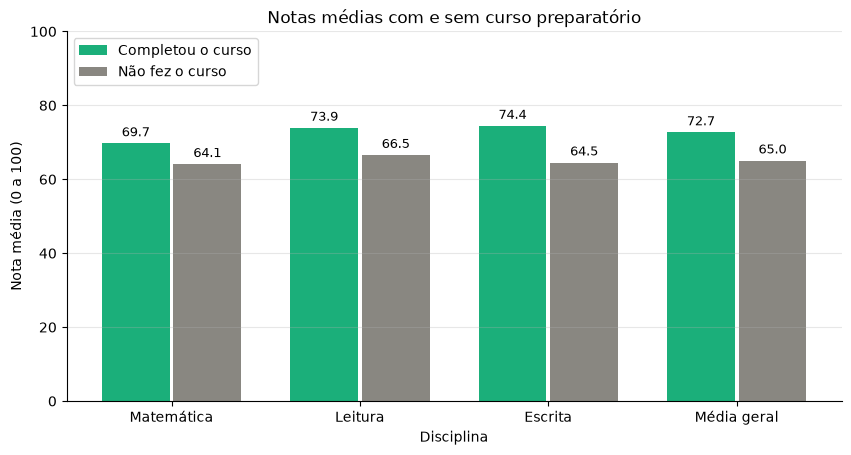

In [45]:
media_curso = alunos.groupby("test preparation course")[NOTAS + ["media_geral"]].mean().rename(columns=NOME_NOTA)
rotulo_curso = {"completed": "Completou o curso", "none": "Não fez o curso"}
x = np.arange(media_curso.shape[1])
largura = 0.38

fig, ax = plt.subplots(figsize=(10, 4.8))
for i, curso in enumerate(["completed", "none"]):
    barras = ax.bar(x + (i - 0.5) * largura, media_curso.loc[curso], width=largura - 0.02,
                    color=COR_CURSO[curso], label=rotulo_curso[curso])
    rotular_barras(ax, barras, "{:.1f}")
ax.set_xticks(x, media_curso.columns)
ax.set_title("Notas médias com e sem curso preparatório")
ax.set_xlabel("Disciplina")
ax.set_ylabel("Nota média (0 a 100)")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
plt.show()

Em todas as disciplinas o grupo que completou o curso tem média maior. A distância é maior em
Escrita (74,4 × 64,5) e Leitura (73,9 × 66,5) do que em Matemática (69,7 × 64,1): a vantagem
aparente do curso é mais forte nas provas de linguagem.

### Gráfico 5 (livre escolha): Matemática × Leitura, aluno a aluno, por gênero

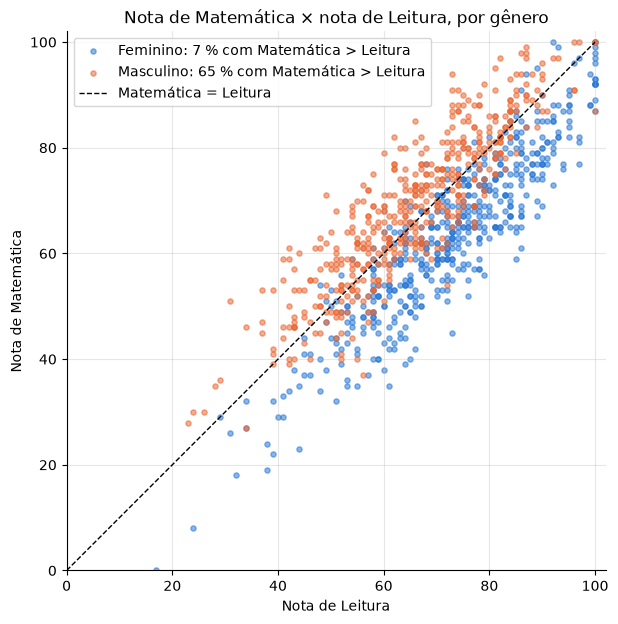

Diferença média (Matemática − Leitura) por gênero: {'female': -8.97, 'male': 3.26}
Correlação Matemática × Leitura: 0.82


In [46]:
fig, ax = plt.subplots(figsize=(8, 7))
for genero in ["female", "male"]:
    g = alunos[alunos["gender"] == genero]
    acima = (g["math score"] > g["reading score"]).mean() * 100
    ax.scatter(g["reading score"], g["math score"], s=14, alpha=0.55, color=COR_GENERO[genero],
               label=f"{rotulo_genero[genero]}: {acima:.0f} % com Matemática > Leitura")
ax.plot([0, 100], [0, 100], color="black", linestyle="--", linewidth=1, label="Matemática = Leitura")
ax.set_title("Nota de Matemática × nota de Leitura, por gênero")
ax.set_xlabel("Nota de Leitura")
ax.set_ylabel("Nota de Matemática")
ax.set_xlim(0, 102)
ax.set_ylim(0, 102)
ax.set_aspect("equal")
ax.legend(loc="upper left")
plt.show()

dif = (alunos["math score"] - alunos["reading score"]).groupby(alunos["gender"]).mean()
print("Diferença média (Matemática − Leitura) por gênero:", dif.round(2).to_dict())
print(f"Correlação Matemática × Leitura: {alunos['math score'].corr(alunos['reading score']):.2f}")

**Descoberta.** Cada ponto é um aluno; acima da diagonal, ele foi melhor em Matemática do que em
Leitura. As duas nuvens são quase paralelas à diagonal (correlação de 0,82: quem vai bem em uma
prova tende a ir bem na outra), mas ficam **em lados opostos dela**: 65 % dos meninos têm
Matemática maior que Leitura, contra apenas 7 % das meninas. Em média, os meninos tiram 3,3 pontos
a mais em Matemática do que em Leitura e as meninas, 9,0 pontos a menos. A diferença de gênero,
portanto, não é de "nível" geral, mas de **perfil**: ela aparece de forma consistente no
indivíduo, não só na média do grupo.

## 7. Investigação livre

Quatro perguntas próprias, duas por base, seguindo o roteiro
**pergunta → seleção/tratamento → análise com Pandas → gráfico → conclusão**.

### Netflix, pergunta 1: O público-alvo do que a Netflix adiciona mudou entre 2016 e 2021, e de forma diferente para filmes e séries?

A questão 2.4 mostrou as classificações mais frequentes no catálogo inteiro, como uma foto. A
pergunta aqui é sobre a **evolução**: **entre os títulos adicionados a cada ano, a parcela de
conteúdo adulto, adolescente, familiar e infantil mudou? A mudança foi a mesma em filmes e séries?**

**Seleção/tratamento.** As 14 classificações (sistemas de cinema e de TV dos EUA) são agrupadas em
4 **faixas de público** equivalentes: *Infantil* (TV-Y, TV-Y7, TV-Y7-FV, TV-G, G), *Família*
(PG, TV-PG), *Adolescente* (PG-13, TV-14) e *Adulto* (R, TV-MA, NC-17). Ficam de fora os 83
títulos sem classificação (NR/UR) e os 7 sem `rating` (incluindo os 3 corrigidos em 1.9). Usa-se o
**ano de adição**, que reflete a decisão de catálogo, no período 2016-2021 (antes de 2016 foram
adicionados menos de 100 títulos por ano). A participação de cada faixa é calculada dentro de
cada combinação tipo × ano, para que filmes e séries sejam comparáveis apesar dos volumes
diferentes.

In [47]:
FAIXA_PUBLICO = {
    "TV-Y": "Infantil", "TV-Y7": "Infantil", "TV-Y7-FV": "Infantil", "TV-G": "Infantil", "G": "Infantil",
    "PG": "Família", "TV-PG": "Família",
    "PG-13": "Adolescente", "TV-14": "Adolescente",
    "R": "Adulto", "TV-MA": "Adulto", "NC-17": "Adulto",
}
ORDEM_FAIXAS = ["Infantil", "Família", "Adolescente", "Adulto"]

netflix_tratado["faixa_publico"] = netflix_tratado["rating"].map(FAIXA_PUBLICO)
print("Sem faixa (NR, UR ou rating ausente):", netflix_tratado["faixa_publico"].isna().sum())

publico = netflix_tratado.dropna(subset=["faixa_publico"])
publico = publico[publico["ano_adicao"].between(2016, 2021)]

print("\nTítulos analisados por tipo e ano de adição:")
display(pd.crosstab(publico["type"], publico["ano_adicao"]))

faixas_ano = (pd.crosstab([publico["type"], publico["ano_adicao"]], publico["faixa_publico"],
                          normalize="index")[ORDEM_FAIXAS] * 100)
print("Participação (%) de cada faixa nos títulos adicionados (cada linha soma 100 %):")
display(faixas_ano.round(1))

print("Período inteiro (2016-2021), por tipo:")
display((pd.crosstab(publico["type"], publico["faixa_publico"], normalize="index")[ORDEM_FAIXAS] * 100).round(1))
for tipo in ["Movie", "TV Show"]:
    var = faixas_ano.loc[(tipo, 2021)] - faixas_ano.loc[(tipo, 2016)]
    print(f"Variação 2016 -> 2021 ({tipo:<7}, p.p.):", var.round(1).to_dict())

Sem faixa (NR, UR ou rating ausente): 90

Títulos analisados por tipo e ano de adição:


ano_adicao,2016,2017,2018,2019,2020,2021
type,,,,,,
Movie,224,814,1223,1418,1284,993
TV Show,175,346,411,592,595,505


Participação (%) de cada faixa nos títulos adicionados (cada linha soma 100 %):


faixa_publico       Infantil  Família  Adolescente  Adulto
type    ano_adicao                                        
Movie   2016             9.8     12.5         20.5    57.1
        2017             7.1     15.0         26.3    51.6
        2018             6.0     13.1         33.1    47.8
        2019             5.4     14.5         32.9    47.2
        2020             9.0     13.9         32.8    44.4
        2021             8.6     11.7         34.8    44.9
TV Show 2016            24.6     14.3         33.1    28.0
        2017            14.5     18.8         39.9    26.9
        2018            14.8     13.9         24.1    47.2
        2019            13.5     12.5         27.4    46.6
        2020            18.8      9.1         23.5    48.6
        2021            21.2      7.7         25.0    46.1

Período inteiro (2016-2021), por tipo:


faixa_publico,Infantil,Família,Adolescente,Adulto
type,,,,
Movie,7.2,13.6,31.9,47.3
TV Show,17.3,12.0,27.6,43.2


Variação 2016 -> 2021 (Movie  , p.p.): {'Infantil': -1.3, 'Família': -0.8, 'Adolescente': 14.3, 'Adulto': -12.2}
Variação 2016 -> 2021 (TV Show, p.p.): {'Infantil': -3.4, 'Família': -6.6, 'Adolescente': -8.2, 'Adulto': 18.1}


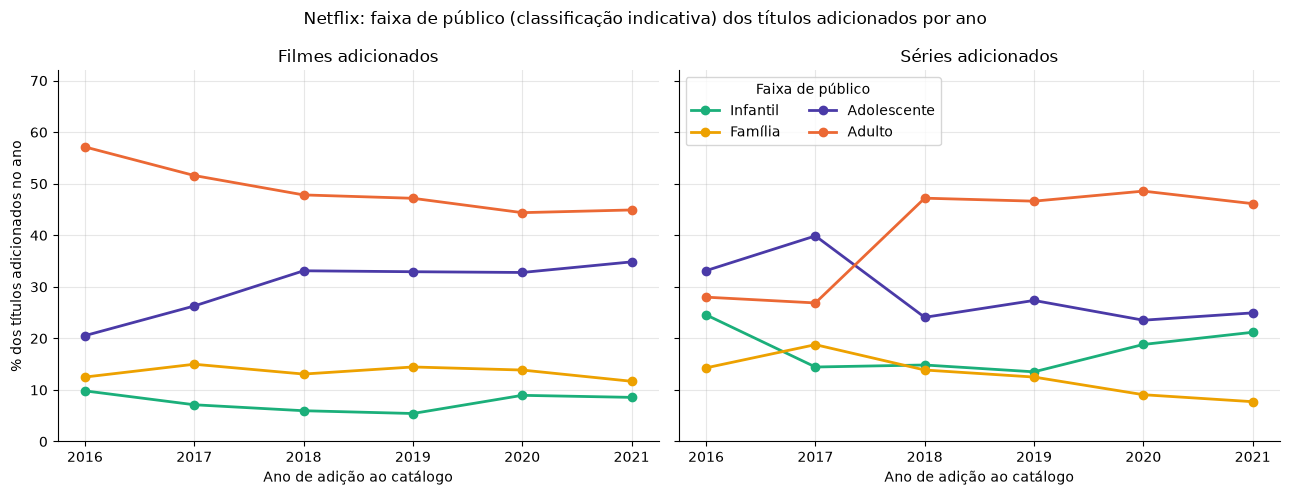

In [48]:
CORES_FAIXA = {"Infantil": VERDE_AGUA, "Família": AMARELO, "Adolescente": VIOLETA, "Adulto": LARANJA}

fig, eixos = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, tipo, nome in zip(eixos, ["Movie", "TV Show"], ["Filmes", "Séries"]):
    dados = faixas_ano.loc[tipo]
    for faixa in ORDEM_FAIXAS:
        ax.plot(dados.index, dados[faixa], marker="o", linewidth=2, color=CORES_FAIXA[faixa], label=faixa)
    ax.set_title(f"{nome} adicionados")
    ax.set_xlabel("Ano de adição ao catálogo")
    ax.set_ylim(0, 72)
eixos[0].set_ylabel("% dos títulos adicionados no ano")
eixos[1].legend(title="Faixa de público", loc="upper left", ncol=2)
fig.suptitle("Netflix: faixa de público (classificação indicativa) dos títulos adicionados por ano")
plt.tight_layout()
plt.show()

**Conclusão.** O público-alvo mudou, e **em direções opostas** nos dois tipos de produção.
Nos **filmes**, o conteúdo adulto perdeu espaço (57,1 % dos adicionados em 2016 → 44,9 % em 2021)
e o adolescente ganhou (20,5 % → 34,8 %): o catálogo de filmes ficou um pouco "mais leve". Nas
**séries** ocorreu o contrário: em 2016-2017 o adulto era só ~27-28 % e a faixa principal era a
adolescente (33-40 %); a partir de 2018 o adulto salta para ~46-49 % e assume a liderança.
Outra diferença estrutural é o **conteúdo infantil**, que pesa muito mais nas séries (17,3 % no
período) do que nos filmes (7,2 %), coerente com o formato episódico das animações infantis. Assim,
o predomínio de TV-MA visto em 2.4 esconde tendências opostas: o conteúdo adulto passou a ser
puxado pelas séries, e não mais pelos filmes. Limitação: a faixa é derivada de dois sistemas de
classificação diferentes (cinema e TV) agrupados por equivalência, e os volumes de séries em
2016 são pequenos, o que torna as porcentagens desse ano menos estáveis.

### Netflix, pergunta 2: Filmes e séries chegam "frescos" ao catálogo, ou a Netflix compra acervo antigo?

O Gráfico 3 mostrou que muitos títulos antigos só foram adicionados depois de 2016. A pergunta é:
**quanto tempo se passa entre o lançamento de um título e sua entrada no catálogo, e isso é
diferente para filmes e séries? Mudou ao longo dos anos?**

**Seleção/tratamento.** Cria-se a coluna `defasagem = ano_adicao − release_year`. Considera-se
"lançamento recente" o título adicionado até 1 ano após o lançamento. Excluem-se os 10 títulos
sem data de adição e restringe-se a 2016-2021 pelo mesmo motivo da pergunta anterior. Há
14 títulos com defasagem negativa (adicionados antes do lançamento), a maioria séries:
em séries, `release_year` parece registrar o ano da **temporada mais recente**, não da estreia.

In [49]:
netflix_tratado["defasagem"] = netflix_tratado["ano_adicao"] - netflix_tratado["release_year"]
print("Títulos com defasagem negativa:", (netflix_tratado["defasagem"] < 0).sum())
display(netflix_tratado.loc[netflix_tratado["defasagem"] < 0, ["type", "title", "release_year", "ano_adicao"]].head())

periodo = netflix_tratado[netflix_tratado["ano_adicao"].between(2016, 2021)].copy()
periodo["recente"] = periodo["defasagem"] <= 1

print("Defasagem (anos) por tipo, 2016-2021:")
display(periodo.groupby("type")["defasagem"].describe())

mediana_defasagem = periodo.groupby(["ano_adicao", "type"])["defasagem"].median().unstack()
pct_recente = periodo.groupby(["ano_adicao", "type"])["recente"].mean().unstack() * 100
display(pd.concat({"mediana da defasagem (anos)": mediana_defasagem,
                   "% lançamentos recentes": pct_recente.round(1)}, axis=1))

Títulos com defasagem negativa: 14


,type,title,release_year,ano_adicao
1551,TV Show,Hilda,2021,2020
1696,TV Show,Polly Pocket,2021,2020
2920,TV Show,Love Is Blind,2021,2020
3168,TV Show,Fuller House,2020,2019
3287,TV Show,Maradona in Mexico,2020,2019


Defasagem (anos) por tipo, 2016-2021:


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Movie,6030.0,5.77,9.77,-1.0,0.0,2.0,7.0,75.0
TV Show,2629.0,2.28,5.3,-2.0,0.0,0.0,2.0,93.0


mediana da defasagem (anos)         % lançamentos recentes        
type                             Movie TV Show                  Movie TV Show
ano_adicao                                                                   
2016                               0.0     1.0                   75.5    51.1
2017                               1.0     1.0                   62.8    52.4
2018                               2.0     0.0                   49.0    72.3
2019                               2.0     1.0                   45.9    65.5
2020                               2.0     0.0                   46.0    75.8
2021                               3.0     0.0                   40.0    72.1

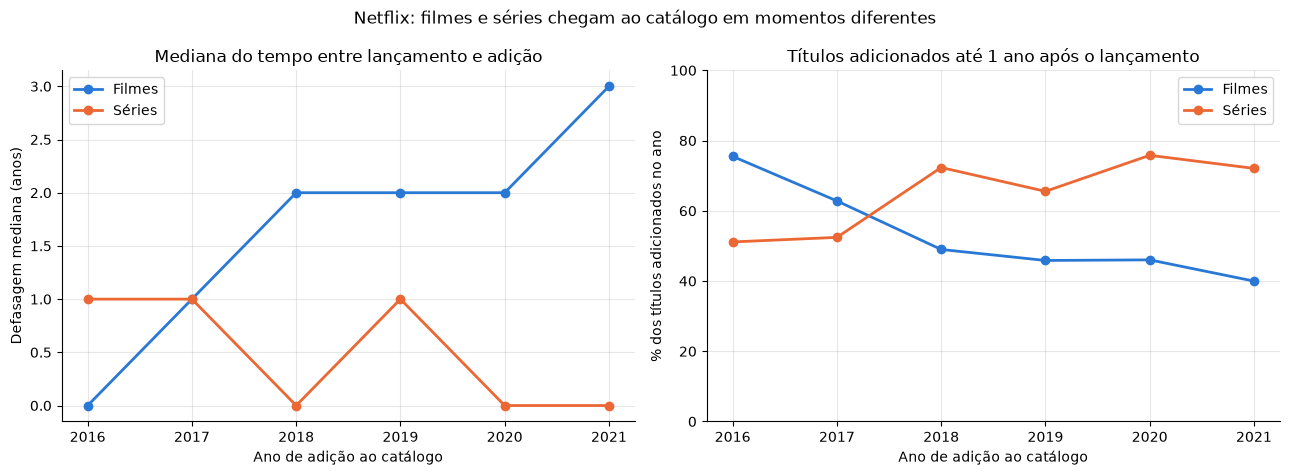

In [50]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8))
for tipo, cor in COR_TIPO.items():
    nome = "Filmes" if tipo == "Movie" else "Séries"
    eixos[0].plot(mediana_defasagem.index, mediana_defasagem[tipo], marker="o", linewidth=2, color=cor, label=nome)
    eixos[1].plot(pct_recente.index, pct_recente[tipo], marker="o", linewidth=2, color=cor, label=nome)

eixos[0].set_title("Mediana do tempo entre lançamento e adição")
eixos[0].set_ylabel("Defasagem mediana (anos)")
eixos[1].set_title("Títulos adicionados até 1 ano após o lançamento")
eixos[1].set_ylabel("% dos títulos adicionados no ano")
eixos[1].set_ylim(0, 100)
for ax in eixos:
    ax.set_xlabel("Ano de adição ao catálogo")
    ax.legend()
fig.suptitle("Netflix: filmes e séries chegam ao catálogo em momentos diferentes")
plt.tight_layout()
plt.show()

**Conclusão.** Filmes e séries seguiram caminhos opostos. Em 2016, 75,5 % dos filmes adicionados
eram lançamentos recentes; em 2021, apenas **40,0 %**, e a defasagem mediana dos filmes subiu de 0
para **3 anos**. Nas séries aconteceu o contrário: a parcela de lançamentos recentes subiu de 51 %
para cerca de **72 %**, com defasagem mediana de 0 a 1 ano em todo o período. Em resumo, no período a Netflix
passou a usar **séries como conteúdo novo** (coerente com o investimento em produções próprias)
e **filmes como acervo licenciado**, o que explica os filmes de 1942 adicionados em 2017 e a
diferença entre as duas curvas do Gráfico 3. Limitação: a base não indica se o título é original
Netflix, então essa leitura é uma inferência a partir das datas.

### Estudantes, pergunta 1: O curso preparatório compensa a desvantagem socioeconômica?

O tipo de almoço (`lunch`: *standard* × *free/reduced*, isto é, gratuito ou subsidiado) é o melhor
indicador socioeconômico disponível. A pergunta é: **o ganho aparente do curso preparatório é o
mesmo para os dois tipos de almoço? Um aluno de almoço subsidiado que faz o curso alcança quem
tem almoço padrão e não fez?**

**Seleção/tratamento.** Cruza-se `lunch` com `test preparation course`, formando 4 grupos, e
compara-se média geral e taxa de aprovação (média ≥ 70). O tamanho de cada grupo é mostrado
para avaliar a confiabilidade das médias.

In [51]:
cruzamento = alunos.pivot_table(index="lunch", columns="test preparation course",
                                values="media_geral", aggfunc=["size", "mean"])
aprov_cruz = alunos.pivot_table(index="lunch", columns="test preparation course",
                                values="aprovado", aggfunc="mean") * 100
display(cruzamento.round(2))
display(aprov_cruz.round(1).add_prefix("aprovação (%) "))

ganho_curso = cruzamento["mean"]["completed"] - cruzamento["mean"]["none"]
print("Ganho aparente do curso na média geral, por tipo de almoço:", ganho_curso.round(2).to_dict())
print(f"Almoço subsidiado + curso  : {cruzamento['mean'].loc['free/reduced', 'completed']:.2f}")
print(f"Almoço padrão + sem curso  : {cruzamento['mean'].loc['standard', 'none']:.2f}")

size           mean       
test preparation course completed none completed   none
lunch                                                  
free/reduced                  131  224     67.76  58.95
standard                      227  418     75.51  68.30

test preparation course,aprovação (%) completed,aprovação (%) none
lunch,,
free/reduced,47.3,21.4
standard,68.7,46.2


Ganho aparente do curso na média geral, por tipo de almoço: {'free/reduced': 8.81, 'standard': 7.2}
Almoço subsidiado + curso  : 67.76
Almoço padrão + sem curso  : 68.30


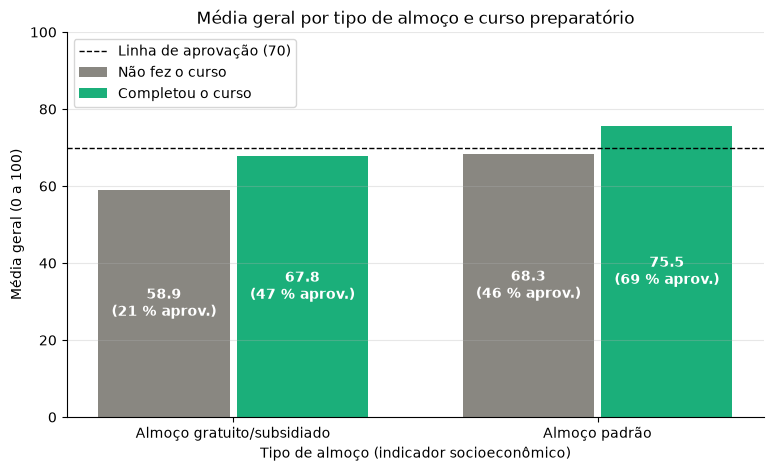

In [52]:
rotulo_almoco = {"free/reduced": "Almoço gratuito/subsidiado", "standard": "Almoço padrão"}
medias_cruz = cruzamento["mean"]
x = np.arange(len(medias_cruz))
largura = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
for i, curso in enumerate(["none", "completed"]):
    barras = ax.bar(x + (i - 0.5) * largura, medias_cruz[curso], width=largura - 0.02,
                    color=COR_CURSO[curso], label=rotulo_curso[curso])
    ax.bar_label(barras, labels=[f"{m:.1f}\n({a:.0f} % aprov.)" for m, a in zip(medias_cruz[curso], aprov_cruz[curso])],
                 label_type="center", color="white", fontsize=10, fontweight="bold")
ax.axhline(70, color="black", linestyle="--", linewidth=1, label="Linha de aprovação (70)")
ax.set_xticks(x, [rotulo_almoco[l] for l in medias_cruz.index])
ax.set_title("Média geral por tipo de almoço e curso preparatório")
ax.set_xlabel("Tipo de almoço (indicador socioeconômico)")
ax.set_ylabel("Média geral (0 a 100)")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
plt.show()

**Conclusão.** O curso está associado a um ganho **um pouco maior** entre os alunos de almoço
subsidiado (+8,8 pontos, de 58,95 para 67,76) do que entre os de almoço padrão (+7,2, de 68,30
para 75,51), e mais que dobra a aprovação desse grupo (21 % → 47 %). Ainda assim, ele **não
compensa totalmente** a desvantagem: o aluno de almoço subsidiado que fez o curso (67,76) fica
ligeiramente abaixo do aluno de almoço padrão que não fez (68,30), e só o grupo "almoço padrão +
curso" supera, em média, a linha de 70. Os dois fatores parecem somar efeitos de tamanho parecido
(~7 a 9 pontos cada). Por ser análise descritiva, isso é associação, não efeito causal.

### Estudantes, pergunta 2: Quais fatores mais concentram os alunos em risco, e o que acontece quando eles se acumulam?

A análise de 5.6 olha os aprovados; aqui o foco é a outra ponta. A pergunta é: **qual fator está
mais associado a estar em situação de risco (média geral < 50)? E como o risco cresce quando um
aluno acumula desvantagens?**

**Seleção/tratamento.** Cria-se `risco = media_geral < 50` (103 alunos, 10,3 %). Para cada fator
categórico calcula-se a taxa de risco de cada categoria e a **amplitude** (maior taxa − menor
taxa), que mede o quanto o fator separa os alunos. Depois conta-se, para cada aluno, quantas de
três desvantagens ele acumula: almoço subsidiado, não ter feito o curso e pais com no máximo
ensino médio (*high school* ou *some high school*).

In [53]:
alunos["risco"] = alunos["media_geral"] < 50
print(f"Alunos em risco (média geral < 50): {alunos['risco'].sum()} ({alunos['risco'].mean() * 100:.1f} %)\n")

FATORES = ["parental level of education", "race/ethnicity", "lunch", "test preparation course", "gender"]
taxas = {f: alunos.groupby(f)["risco"].mean() * 100 for f in FATORES}
amplitude = pd.DataFrame({
    "maior taxa (%)": {f: t.max() for f, t in taxas.items()},
    "categoria": {f: t.idxmax() for f, t in taxas.items()},
    "menor taxa (%)": {f: t.min() for f, t in taxas.items()},
    "categoria ": {f: t.idxmin() for f, t in taxas.items()},
})
amplitude["amplitude (p.p.)"] = amplitude["maior taxa (%)"] - amplitude["menor taxa (%)"]
display(amplitude.sort_values("amplitude (p.p.)", ascending=False).round(1))

alunos["desvantagens"] = ((alunos["lunch"] == "free/reduced").astype(int)
                          + (alunos["test preparation course"] == "none")
                          + alunos["parental level of education"].isin(["high school", "some high school"]))
acumulo = alunos.groupby("desvantagens").agg(alunos=("risco", "size"), risco=("risco", "mean"),
                                             media_geral=("media_geral", "mean"), aprovacao=("aprovado", "mean"))
acumulo[["risco", "aprovacao"]] *= 100
display(acumulo.round(1))

Alunos em risco (média geral < 50): 103 (10.3 %)



,maior taxa (%),categoria,menor taxa (%),categoria,amplitude (p.p.)
parental level of education,16.8,high school,1.7,master's degree,15.1
race/ethnicity,18.0,group A,6.4,group E,11.5
lunch,17.2,free/reduced,6.5,standard,10.7
test preparation course,13.2,none,5.0,completed,8.2
gender,13.3,male,7.5,female,5.7


,alunos,risco,media_geral,aprovacao
desvantagens,,,,
0,141,0.0,78.2,76.6
1,430,7.0,70.1,52.3
2,345,11.9,64.0,32.8
3,84,38.1,53.9,15.5


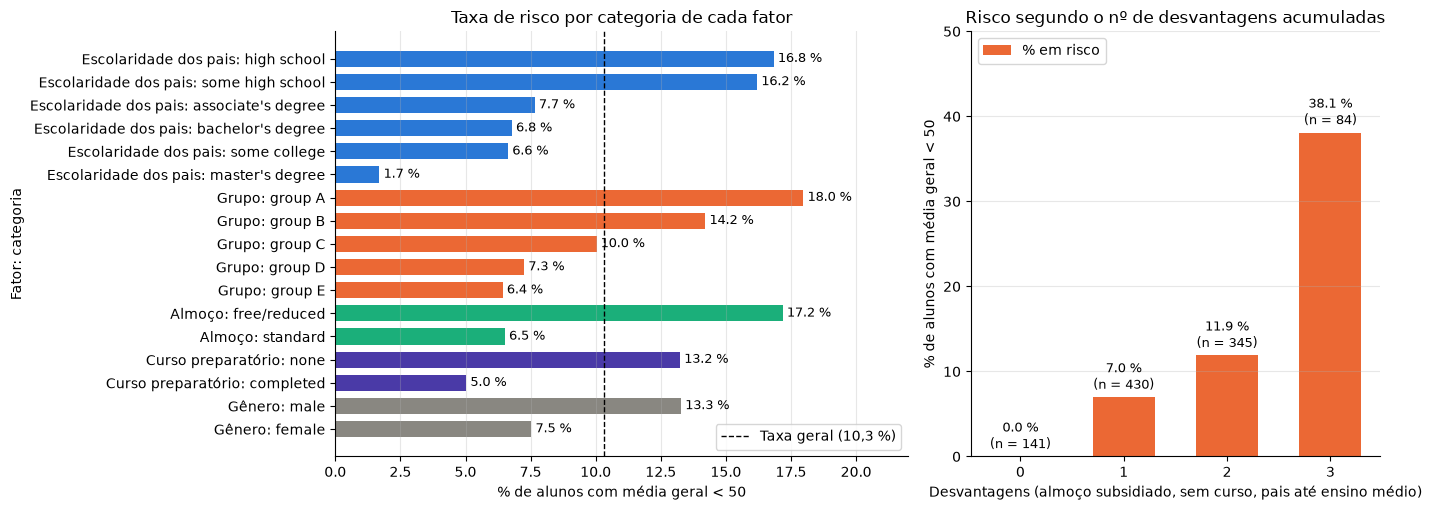

In [54]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})

# (a) taxa de risco por categoria, agrupada por fator
nomes_fator = {"parental level of education": "Escolaridade dos pais", "race/ethnicity": "Grupo",
               "lunch": "Almoço", "test preparation course": "Curso preparatório", "gender": "Gênero"}
ordem_fatores = amplitude.sort_values("amplitude (p.p.)").index
rotulos, valores, cores = [], [], []
for cor, f in zip([CINZA, VIOLETA, VERDE_AGUA, LARANJA, AZUL], ordem_fatores):
    t = taxas[f].sort_values()
    rotulos += [f"{nomes_fator[f]}: {c}" for c in t.index]
    valores += list(t.values)
    cores += [cor] * len(t)
barras = eixos[0].barh(rotulos, valores, color=cores, height=0.7)
rotular_barras(eixos[0], barras, "{:.1f} %")
eixos[0].axvline(alunos["risco"].mean() * 100, color="black", linestyle="--", linewidth=1, label="Taxa geral (10,3 %)")
eixos[0].set_title("Taxa de risco por categoria de cada fator")
eixos[0].set_xlabel("% de alunos com média geral < 50")
eixos[0].set_ylabel("Fator: categoria")
eixos[0].set_xlim(0, 22)
eixos[0].grid(axis="y", visible=False)
eixos[0].legend(loc="lower right")

# (b) risco segundo o número de desvantagens acumuladas
barras = eixos[1].bar(acumulo.index.astype(str), acumulo["risco"], color=LARANJA, width=0.6, label="% em risco")
eixos[1].bar_label(barras, labels=[f"{r:.1f} %\n(n = {n})" for r, n in zip(acumulo["risco"], acumulo["alunos"])], padding=3, fontsize=9)
eixos[1].set_title("Risco segundo o nº de desvantagens acumuladas")
eixos[1].set_xlabel("Desvantagens (almoço subsidiado, sem curso, pais até ensino médio)")
eixos[1].set_ylabel("% de alunos com média geral < 50")
eixos[1].set_ylim(0, 50)
eixos[1].grid(axis="x", visible=False)
eixos[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

**Conclusão.** Individualmente, a **escolaridade dos pais** é o fator que mais separa os alunos:
a taxa de risco vai de 1,7 % (*master's degree*) a 16,8 % (*high school*), amplitude de 15,1 p.p.;
em seguida vêm o grupo (A: 18,0 % × E: 6,4 %), o almoço (17,2 % × 6,5 %) e o curso preparatório
(13,2 % × 5,0 %). O gênero é o que menos separa (13,3 % × 7,5 %). O resultado mais forte, porém,
é o **acúmulo**: nenhum dos 141 alunos sem nenhuma das três desvantagens está em risco, enquanto
**38,1 %** dos 84 que têm as três estão, e a aprovação despenca de 76,6 % para 15,5 %. Os fatores
se somam, então políticas de apoio deveriam priorizar quem acumula desvantagens, não um fator
isolado. Cuidado: *master's degree* tem só 59 alunos (1 em risco), o que torna essa taxa instável.

## 8. Conclusões

### Descobertas sobre a Netflix

1. **O catálogo é majoritariamente de filmes e de conteúdo recente.** São 69,6 % de filmes, e
   85 % dos títulos foram lançados de 2010 em diante (67 % só na década de 2010). As
   classificações adultas/adolescentes (TV-MA e TV-14) somam 61 % do catálogo.
2. **Os EUA dominam, mas o catálogo é muito internacional.** Os EUA aparecem em 3.690 títulos,
   mais que o triplo da Índia; ainda assim, 46,6 % dos títulos estão em categorias
   "International".
3. **O público-alvo mudou em direções opostas.** Entre 2016 e 2021, o conteúdo adulto caiu de
   57 % para 45 % dos filmes adicionados (com alta do adolescente), mas subiu de 28 % para 46 % das
   séries adicionadas; as séries também concentram muito mais conteúdo infantil (17 % × 7 %).
4. **Filmes e séries têm papéis diferentes no catálogo.** Entre 2016 e 2021 a fração de filmes
   adicionados logo após o lançamento caiu de 75,5 % para 40 % (defasagem mediana de 0 para 3
   anos), enquanto nas séries subiu de 51 % para 72 %: séries como conteúdo novo, filmes como
   acervo licenciado (inclusive documentários de 1942 adicionados em 2017).
5. Filmes têm duração típica entre 90 e 102 minutos (mediana de 98 min), sem uma duração
   única dominante.

### Descobertas sobre o desempenho dos estudantes

1. **Só 45,9 % atingem média 70**; as médias das três provas (66 a 69) são próximas, com
   Matemática um pouco abaixo e Leitura um pouco acima.
2. **A diferença de gênero é de perfil, não de nível.** As meninas têm média geral maior
   (69,6 × 65,8) porque vão melhor em Leitura e Escrita, mas os meninos vão melhor em
   Matemática; aluno a aluno, 65 % dos meninos têm Matemática > Leitura, contra 7 % das meninas.
3. **Curso preparatório, almoço, escolaridade dos pais e grupo estão todos associados ao
   desempenho**, cada um com diferenças de ~7 a 10 pontos na média geral. O curso está associado
   a +7,6 pontos (mais em Escrita, menos em Matemática) e a um ganho um pouco maior entre alunos de
   almoço subsidiado, mas não compensa sozinho a desvantagem socioeconômica.
4. **As desvantagens se acumulam.** Nenhum aluno sem desvantagens está em risco (média < 50),
   contra 38,1 % dos que acumulam as três (almoço subsidiado, sem curso, pais até ensino médio).

### Características das bases que dificultaram as análises

* **Netflix:** colunas multivaloradas (`country`, `director`, `cast`, `listed_in`) exigiram
  "explodir" listas antes de contar, e os resultados mudam muito com isso (Reino Unido: 419 × 806);
  30 % dos diretores ausentes (quase todas as séries); `duration` misturando minutos e temporadas;
  datas como texto com espaços extras; três registros com colunas deslocadas; `release_year` de
  séries aparentemente referente à última temporada (defasagens negativas); 2021 incompleto.
* **Estudantes:** a base é limpa, mas pobre em contexto: os grupos de `race/ethnicity` são
  anônimos, não há idade, escola, região ou ano, e `lunch` é apenas um indicador indireto de nível
  socioeconômico. Algumas categorias são pequenas (*master's degree*: 59 alunos), o que torna
  suas médias instáveis.

### Qual base permitiu análises mais interessantes, e por quê

A **Netflix** permitiu análises mais ricas, justamente por ser mais "suja" e mais variada: tem
dimensão temporal dupla (lançamento e adição ao catálogo), texto multivalorado, dados geográficos
e dois tipos de produto, o que possibilitou perguntas sobre *estratégia* (público-alvo,
acervo × lançamentos) que não aparecem em nenhuma contagem direta. A base de **estudantes** é
ideal para praticar agrupamentos e comparações de médias, mas, por ter só 8 colunas, sem contexto
temporal ou geográfico, suas perguntas convergem para "qual grupo tem média maior"; o achado mais
interessante dela (a inversão de perfil por gênero) só apareceu ao olhar os alunos
individualmente, e não as médias.

### Limitações das análises realizadas

* Todas as conclusões são **descritivas**: não foram feitos testes de hipótese nem controle de
  variáveis de confusão, então as diferenças observadas (curso, almoço, gênero) são associações,
  não efeitos causais.
* A base da Netflix é um **retrato do catálogo em 2021** (região não especificada; títulos já
  removidos não aparecem); não representa toda a produção audiovisual nem a audiência, e não
  indica quais títulos são originais Netflix, então a leitura de "estratégia" é inferida a partir
  das datas.
* Contar coproduções para cada país infla os totais (um título conta várias vezes), e títulos
  sem país/diretor ficaram fora dos rankings correspondentes.
* A base de estudantes é **sintética** e pequena (1.000 alunos), sem origem amostral conhecida;
  os resultados servem para praticar a análise, não para generalizar sobre estudantes reais.
* Os cortes de aprovação (≥ 70) e de risco (< 50) são escolhas arbitrárias; outros cortes mudariam
  os percentuais, embora não a ordem dos grupos.